# Experiment 6 — A simple neural network
CSAI4014 AISR Laboratory · Lab Manual, Chapter 7

A 2-4-1 sigmoid network written in NumPy only, trained on XOR by backpropagation and full-batch gradient
descent. Four learning rates are compared (0.05, 0.5, 2.0 and 10.0, the last as the manual suggests);
the decision boundary of the best run is drawn over the input plane.

In [1]:
import json, os, platform, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figs", exist_ok=True)
RESULTS = {}                      # every number the report quotes is stored here

def save(fig, name):
    """Save a figure into figs/ (150 dpi PNG, as the report guidelines ask)."""
    fig.savefig(os.path.join("figs", name), bbox_inches="tight")

def env_info():
    info = {"python": platform.python_version(), "numpy": np.__version__,
            "matplotlib": matplotlib.__version__, "os": f"{platform.system()} {platform.release()}",
            "cpu": platform.processor() or platform.machine()}
    try:
        import scipy; info["scipy"] = scipy.__version__
    except ImportError:
        pass
    return info

RESULTS["env"] = env_info()
print(RESULTS["env"])

{'python': '3.12.1', 'numpy': '2.3.2', 'matplotlib': '3.8.4', 'os': 'Windows 11', 'cpu': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'scipy': '1.16.1'}


## 1. Forward pass and loss

In [2]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)          # XOR

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

HIDDEN, SEED, EPOCHS = 4, 1, 20000

def init(seed=SEED, hidden=HIDDEN):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, 1, (2, hidden)); b1 = np.zeros((1, hidden))
    W2 = rng.normal(0, 1, (hidden, 1)); b2 = np.zeros((1, 1))
    return W1, b1, W2, b2

def forward(params, Xin):
    W1, b1, W2, b2 = params
    h = sigmoid(Xin @ W1 + b1)                 # hidden activations, N x hidden
    o = sigmoid(h @ W2 + b2)                   # output, N x 1
    return h, o

_, o0 = forward(init(), X)
print("initial loss:", float(np.mean((o0 - y)**2)))
RESULTS["initial_loss"] = float(np.mean((o0 - y)**2))

initial loss: 0.2748629616482994


## 2. Backpropagation and training

In [3]:
def train_xor(lr, epochs=EPOCHS, seed=SEED, hidden=HIDDEN):
    W1, b1, W2, b2 = init(seed, hidden)
    loss = []
    for _ in range(epochs):
        h = sigmoid(X @ W1 + b1)               # forward
        o = sigmoid(h @ W2 + b2)
        loss.append(float(np.mean((o - y)**2)))

        do = (o - y) * o * (1 - o)             # backward: output delta
        dW2 = h.T @ do; db2 = do.sum(0, keepdims=True)
        dh = (do @ W2.T) * h * (1 - h)         # hidden delta
        dW1 = X.T @ dh; db1 = dh.sum(0, keepdims=True)

        W2 -= lr*dW2; b2 -= lr*db2             # gradient descent
        W1 -= lr*dW1; b1 -= lr*db1
    return (W1, b1, W2, b2), np.array(loss)

def converged(params, loss):
    """Converged = final MSE below 1e-3 AND all four outputs on the correct side of 0.5."""
    _, o = forward(params, X)
    return bool(loss[-1] < 1e-3 and np.all((o > 0.5) == (y > 0.5)))

## 3. Learning rate and the decision boundary

lr =  0.05: final MSE = 2.31e-03, converged = False, MSE < 0.01 from epoch 10851
lr =   0.5: final MSE = 1.11e-04, converged = True, MSE < 0.01 from epoch 1086
lr =   2.0: final MSE = 2.46e-05, converged = True, MSE < 0.01 from epoch 272
lr =  10.0: final MSE = 5.81e-06, converged = True, MSE < 0.01 from epoch 70


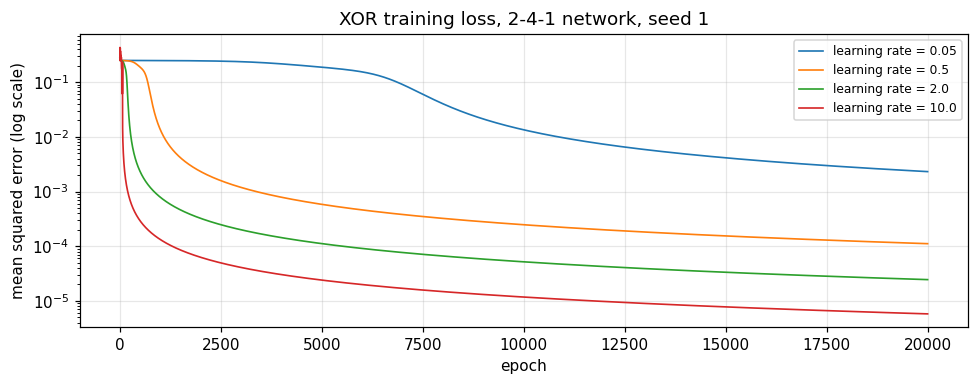

best run: lr = 10.0  predictions: [0.002 0.998 0.998 0.003]


In [4]:
LRS = (0.05, 0.5, 2.0, 10.0)
runs, table = {}, []
fig, ax = plt.subplots(figsize=(9, 3.6))
for lr in LRS:
    params, l = train_xor(lr)
    runs[lr] = (params, l)
    conv = converged(params, l)
    e_below = int(np.argmax(l < 1e-2)) if np.any(l < 1e-2) else None   # first epoch with MSE < 0.01
    table.append({"lr": lr, "final_mse": l[-1], "converged": conv, "epoch_mse_below_0.01": e_below})
    ax.semilogy(l, lw=1.1, label=f"learning rate = {lr}")
    print(f"lr = {lr:>5}: final MSE = {l[-1]:.2e}, converged = {conv}, MSE < 0.01 from epoch {e_below}")
ax.set(xlabel="epoch", ylabel="mean squared error (log scale)", title="XOR training loss, 2-4-1 network, seed 1")
ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "fig6_1_loss.png"); plt.show()
RESULTS["lr_table"] = table

best = min(LRS, key=lambda lr: runs[lr][1][-1])
params = runs[best][0]
_, o = forward(params, X)
RESULTS["best_lr"] = best
RESULTS["predictions"] = [{"x1": int(a), "x2": int(b), "target": int(t), "pred": float(p)}
                          for (a, b), t, p in zip(X, y.ravel(), o.ravel())]
print("best run: lr =", best, " predictions:", o.ravel().round(3))

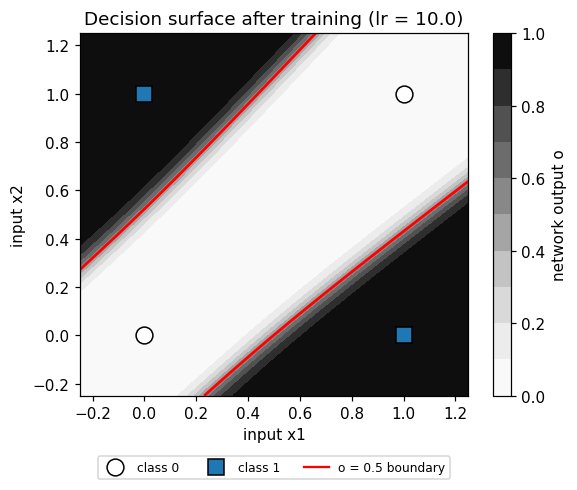

In [5]:
gx, gy = np.meshgrid(np.linspace(-0.25, 1.25, 300), np.linspace(-0.25, 1.25, 300))
G = np.c_[gx.ravel(), gy.ravel()]
Z = forward(params, G)[1].reshape(gx.shape)

fig, ax = plt.subplots(figsize=(5.4, 4.6))
cs = ax.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11), cmap="Greys")
ax.contour(gx, gy, Z, levels=[0.5], colors="r", linewidths=1.8)
fig.colorbar(cs, ax=ax, label="network output o")
for (a, b), t in zip(X, y.ravel()):
    ax.plot(a, b, "o" if t == 0 else "s", ms=11, mfc="w" if t == 0 else "tab:blue", mec="k",
            label="class 0" if (t == 0 and a == 0) else ("class 1" if (t == 1 and a == 0) else None))
ax.plot([], [], "r-", label="o = 0.5 boundary")
ax.set(xlabel="input x1", ylabel="input x2", title=f"Decision surface after training (lr = {best})")
ax.legend(fontsize=8, loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.15)); ax.grid(False)
fig.tight_layout(); save(fig, "fig6_2_decision_boundary.png"); plt.show()

## 4. Check: zero initialisation cannot learn XOR

In [6]:
W1 = np.zeros((2, HIDDEN)); b1 = np.zeros((1, HIDDEN)); W2 = np.zeros((HIDDEN, 1)); b2 = np.zeros((1, 1))
for _ in range(EPOCHS):
    h = sigmoid(X @ W1 + b1); o = sigmoid(h @ W2 + b2)
    do = (o - y)*o*(1 - o); dh = (do @ W2.T)*h*(1 - h)
    W2 -= 2.0*(h.T @ do); b2 -= 2.0*do.sum(0, keepdims=True)
    W1 -= 2.0*(X.T @ dh); b1 -= 2.0*dh.sum(0, keepdims=True)
print("zero init, lr 2.0: final MSE =", round(float(np.mean((o - y)**2)), 4),
      "; hidden columns identical:", bool(np.allclose(W1, W1[:, :1])))
RESULTS["zero_init_mse"] = float(np.mean((o - y)**2))

zero init, lr 2.0: final MSE = 0.25 ; hidden columns identical: True


In [7]:
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("saved results.json and", len(os.listdir("figs")), "figures in figs/")

saved results.json and 2 figures in figs/
